In [ ]:
!pip install -q kagglehub nltk

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub
import nltk

print("GPU:", tf.config.list_physical_devices('GPU'))

path = kagglehub.dataset_download(
    "shashwatwork/consume-complaints-dataset-fo-nlp"
)

csv_path = os.path.join(path, "complaints_processed.csv")
df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.
Dataset loaded successfully!
Shape: (162421, 3)


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


In [ ]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nExact Duplicate Rows:")
print(df.duplicated().sum())

print("\nUnique Products:")
print(df['product'].unique())

print("\nClass Distribution:")
print(df['product'].value_counts())

print("\nDuplicate Narratives:")
print(df['narrative'].duplicated().sum())

print("\nConflicting Labels:")
print(
    (df.groupby('narrative')['product'].nunique() > 1).sum()
)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162421 entries, 0 to 162420
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  162421 non-null  int64 
 1   product     162421 non-null  object
 2   narrative   162411 non-null  object
dtypes: int64(1), object(2)
memory usage: 3.7+ MB

Missing Values:
Unnamed: 0     0
product        0
narrative     10
dtype: int64

Exact Duplicate Rows:
0

Unique Products:
['credit_card' 'retail_banking' 'credit_reporting' 'mortgages_and_loans'
 'debt_collection']

Class Distribution:
product
credit_reporting       91179
debt_collection        23150
mortgages_and_loans    18990
credit_card            15566
retail_banking         13536
Name: count, dtype: int64

Duplicate Narratives:
37948

Conflicting Labels:
172


In [ ]:
# Remove missing narratives and unnecessary index column
df = df.dropna(subset=['narrative']).copy()
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# Count labels for each unique narrative
label_counts = df.groupby(
    ['narrative', 'product']
).size().unstack(fill_value=0)

# Find narratives with tied majority labels
max_counts = label_counts.max(axis=1)
tied_narratives = (
    label_counts.eq(max_counts, axis=0).sum(axis=1) > 1
)

# Remove tied narratives
label_counts = label_counts.loc[~tied_narratives]

# Keep the majority label for each narrative
df_clean = pd.DataFrame({
    'narrative': label_counts.index,
    'product': label_counts.idxmax(axis=1)
}).reset_index(drop=True)

print("Original rows:", 162421)
print("Rows after cleaning:", len(df_clean))
print("Removed tied narratives:", tied_narratives.sum())
print("Remaining duplicate narratives:",
      df_clean['narrative'].duplicated().sum())

print("\nFinal class distribution:")
print(df_clean['product'].value_counts())

Original rows: 162421
Rows after cleaning: 124420
Removed tied narratives: 52
Remaining duplicate narratives: 0

Final class distribution:
product
credit_reporting       56242
debt_collection        21031
mortgages_and_loans    18706
credit_card            14975
retail_banking         13466
Name: count, dtype: int64


In [ ]:
import nltk
import re
from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

# Preserve important negation words
stop_words -= {'no', 'not', 'nor', 'never', 'without'}

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

df_clean['cleaned_narrative'] = df_clean['narrative'].apply(preprocess_text)

display(df_clean[['narrative', 'cleaned_narrative']].head())

print("Empty cleaned narratives:",
      (df_clean['cleaned_narrative'].str.strip() == '').sum())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,narrative,cleaned_narrative
0,aa citibank mastercard made reservation trip c...,aa citibank mastercard made reservation trip c...
1,aa recovery contacted relative left voicemail ...,aa recovery contacted relative left voicemail ...
2,aaa collection say responsible late wife ambul...,aaa collection say responsible late wife ambul...
3,aafes military star card late time payment tim...,aafes military star card late time payment tim...
4,aafes military star card took advantage overse...,aafes military star card took advantage overse...


Empty cleaned narratives: 0


In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean['cleaned_narrative']
y = df_clean['product']

# 80% Training, 20% Temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the remaining 20% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

Training: 99536
Validation: 12442
Testing: 12442

Training class distribution:
product
credit_reporting       44993
debt_collection        16825
mortgages_and_loans    14965
credit_card            11980
retail_banking         10773
Name: count, dtype: int64


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

MAX_WORDS = 30000
MAX_LEN = 256
NUM_CLASSES = 5

# Tokenization
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)
tokenizer.fit_on_texts(X_train)

# Convert text into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Padding
X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN,
    padding='post', truncating='post'
)
X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN,
    padding='post', truncating='post'
)
X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN,
    padding='post', truncating='post'
)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

# Encode labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

# Handle class imbalance using training data only
classes = np.unique(y_train_encoded)
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train_encoded
)
class_weight_dict = dict(zip(classes, weights))

print("Vocabulary size:", vocab_size)
print("Training shape:", X_train_pad.shape)
print("Validation shape:", X_val_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("\nClass mapping:")
print(dict(enumerate(label_encoder.classes_)))
print("\nClass weights:", class_weight_dict)

Vocabulary size: 30000
Training shape: (99536, 256)
Validation shape: (12442, 256)
Testing shape: (12442, 256)

Class mapping:
{0: 'credit_card', 1: 'credit_reporting', 2: 'debt_collection', 3: 'mortgages_and_loans', 4: 'retail_banking'}

Class weights: {np.int64(0): np.float64(1.661702838063439), np.int64(1): np.float64(0.44245104794079076), np.int64(2): np.float64(1.1831916790490342), np.int64(3): np.float64(1.3302505846976278), np.int64(4): np.float64(1.8478789566508864)}


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pickle
import numpy as np

PROJECT_DIR = '/content/drive/MyDrive/Consumer_Complaint_Classification'
os.makedirs(PROJECT_DIR, exist_ok=True)

# Save tokenizer and label encoder
with open(f'{PROJECT_DIR}/tokenizer.pkl', 'wb') as f:
    pickle.dump(tokenizer, f)

with open(f'{PROJECT_DIR}/label_encoder.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)

# Save processed datasets
np.savez_compressed(
    f'{PROJECT_DIR}/processed_data.npz',
    X_train=X_train_pad,
    X_val=X_val_pad,
    X_test=X_test_pad,
    y_train=y_train_encoded,
    y_val=y_val_encoded,
    y_test=y_test_encoded
)

print("Project folder:", PROJECT_DIR)
print("Preprocessing files saved successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/Consumer_Complaint_Classification
Preprocessing files saved successfully!


In [ ]:
import os

for file in os.listdir(PROJECT_DIR):
    print("✅", file)

✅ tokenizer.pkl
✅ label_encoder.pkl
✅ DistilBERT_checkpoints
✅ DistilBERT_best
✅ processed_data.npz


In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tf.keras.backend.clear_session()

rnn_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=128,
        mask_zero=True
    ),
    SimpleRNN(64),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

rnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

rnn_path = f'{PROJECT_DIR}/SimpleRNN_best.keras'

callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        filepath=rnn_path,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

history_rnn = rnn_model.fit(
    X_train_pad,
    y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=10,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

print("\nTraining finished!")
print("Model saved:", os.path.exists(rnn_path))
if os.path.exists(rnn_path):
    print("File size:", round(os.path.getsize(rnn_path) / (1024**2), 2), "MB")

Epoch 1/10
778/778 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4603 - loss: 1.1596
Epoch 1: val_loss improved from None to 0.82705, saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/SimpleRNN_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/SimpleRNN_best.keras
778/778 ━━━━━━━━━━━━━━━━━━━━ 42s 38ms/step - accuracy: 0.5923 - loss: 0.9730 - val_accuracy: 0.7156 - val_loss: 0.8271
Epoch 2/10
778/778 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6087 - loss: 1.0021
Epoch 2: val_loss did not improve from 0.82705
778/778 ━━━━━━━━━━━━━━━━━━━━ 23s 26ms/step - accuracy: 0.5662 - loss: 1.0765 - val_accuracy: 0.5096 - val_loss: 1.1512
Epoch 3/10
776/778 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.5072 - loss: 1.2011
Epoch 3: val_loss did not improve from 0.82705
778/778 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.4769 - loss: 1.2629 - val_accuracy: 0.5214 - val_loss: 1.1693

Training finished!
Model saved:

In [ ]:
from tensorflow.keras.layers import LSTM

tf.keras.backend.clear_session()

lstm_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, mask_zero=True),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

lstm_path = f'{PROJECT_DIR}/LSTM_best.keras'

callbacks = [
    EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
    ModelCheckpoint(lstm_path, monitor='val_loss', save_best_only=True, verbose=1)
]

history_lstm = lstm_model.fit(
    X_train_pad, y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=10,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

print("\nLSTM saved:", os.path.exists(lstm_path))

Epoch 1/10
778/778 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6097 - loss: 1.0688
Epoch 1: val_loss improved from None to 0.57790, saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/LSTM_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/LSTM_best.keras
778/778 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.7046 - loss: 0.8612 - val_accuracy: 0.8196 - val_loss: 0.5779
Epoch 2/10
778/778 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8179 - loss: 0.5666
Epoch 2: val_loss did not improve from 0.57790
778/778 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8121 - loss: 0.5913 - val_accuracy: 0.7847 - val_loss: 0.6587
Epoch 3/10
776/778 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8045 - loss: 0.6071
Epoch 3: val_loss did not improve from 0.57790
778/778 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.7928 - loss: 0.6371 - val_accuracy: 0.7893 - val_loss: 0.6405

LSTM saved: True


In [ ]:
from tensorflow.keras.layers import LSTM

tf.keras.backend.clear_session()

lstm_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, mask_zero=True),
    LSTM(64),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

lstm_path = f'{PROJECT_DIR}/LSTM_best.keras'

callbacks = [
    EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
    ModelCheckpoint(lstm_path, monitor='val_loss', save_best_only=True, verbose=1)
]

history_lstm = lstm_model.fit(
    X_train_pad, y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=10,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

print("\nLSTM saved:", os.path.exists(lstm_path))

Epoch 1/10
776/778 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6303 - loss: 0.9711
Epoch 1: val_loss improved from None to 0.69534, saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/LSTM_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/LSTM_best.keras
778/778 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.7311 - loss: 0.7821 - val_accuracy: 0.7623 - val_loss: 0.6953
Epoch 2/10
776/778 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7688 - loss: 0.6820
Epoch 2: val_loss improved from 0.69534 to 0.57547, saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/LSTM_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/LSTM_best.keras
778/778 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.7681 - loss: 0.6959 - val_accuracy: 0.8180 - val_loss: 0.5755
Epoch 3/10
777/778 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8146 - loss: 0.5679
Epoch 

In [ ]:
from tensorflow.keras.layers import GRU

tf.keras.backend.clear_session()

gru_model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=128, mask_zero=True),
    GRU(64),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(NUM_CLASSES, activation='softmax')
])

gru_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

gru_path = f'{PROJECT_DIR}/GRU_best.keras'

gru_callbacks = [
    EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True),
    ModelCheckpoint(gru_path, monitor='val_loss', save_best_only=True, verbose=1)
]

history_gru = gru_model.fit(
    X_train_pad, y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=10,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=gru_callbacks
)

print("\nGRU saved correctly:", os.path.exists(gru_path))

Epoch 1/10
778/778 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5804 - loss: 1.0272
Epoch 1: val_loss improved from None to 0.47169, saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/GRU_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/GRU_best.keras
778/778 ━━━━━━━━━━━━━━━━━━━━ 17s 19ms/step - accuracy: 0.7130 - loss: 0.7389 - val_accuracy: 0.8397 - val_loss: 0.4717
Epoch 2/10
776/778 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8405 - loss: 0.4436
Epoch 2: val_loss improved from 0.47169 to 0.46897, saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/GRU_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Consumer_Complaint_Classification/GRU_best.keras
778/778 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8398 - loss: 0.4421 - val_accuracy: 0.8332 - val_loss: 0.4690
Epoch 3/10
778/778 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8603 - loss: 0.3758
Epoch 3: v

In [ ]:
import os
import pandas as pd
import kagglehub

from sklearn.model_selection import train_test_split

# Reload original dataset
path = kagglehub.dataset_download(
    "shashwatwork/consume-complaints-dataset-fo-nlp"
)

df = pd.read_csv(os.path.join(path, "complaints_processed.csv"))

# Clean missing values and remove unnecessary column
df = df.dropna(subset=['narrative']).copy()
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# Resolve duplicate narratives and conflicting labels
label_counts = df.groupby(
    ['narrative', 'product']
).size().unstack(fill_value=0)

max_counts = label_counts.max(axis=1)
tied_narratives = label_counts.eq(max_counts, axis=0).sum(axis=1) > 1

label_counts = label_counts.loc[~tied_narratives]

df_clean = pd.DataFrame({
    'narrative': label_counts.index,
    'product': label_counts.idxmax(axis=1)
}).reset_index(drop=True)

# Recreate the exact same stratified splits
X = df_clean['narrative']
y = df_clean['product']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print("Data restored successfully!")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Using Colab cache for faster access to the 'consume-complaints-dataset-fo-nlp' dataset.
Data restored successfully!
Training: 99536
Validation: 12442
Testing: 12442


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
label_encoder.fit(y_train)

NUM_CLASSES = len(label_encoder.classes_)

print("Classes:", label_encoder.classes_)
print("Number of classes:", NUM_CLASSES)

Classes: ['credit_card' 'credit_reporting' 'debt_collection' 'mortgages_and_loans'
 'retail_banking']
Number of classes: 5


In [ ]:
import os
import numpy as np
import torch

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer
)
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Prepare datasets
train_dataset = Dataset.from_dict({
    "text": X_train.astype(str).tolist(),
    "labels": label_encoder.transform(y_train).tolist()
})

val_dataset = Dataset.from_dict({
    "text": X_val.astype(str).tolist(),
    "labels": label_encoder.transform(y_val).tolist()
})

# Load DistilBERT
model_name = "distilbert-base-uncased"

transformer_tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_function(examples):
    return transformer_tokenizer(
        examples["text"],
        truncation=True,
        max_length=256
    )

train_dataset = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

transformer_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=NUM_CLASSES
)

data_collator = DataCollatorWithPadding(
    tokenizer=transformer_tokenizer
)

# Evaluation metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# Training settings
training_args = TrainingArguments(
    output_dir="/content/DistilBERT_checkpoints",
    num_train_epochs=2,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=torch.cuda.is_available(),
    logging_steps=200,
    report_to="none"
)

trainer = Trainer(
    model=transformer_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=transformer_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# Train
trainer.train()

# Save the trained model
transformer_path = "/content/DistilBERT_best"
trainer.save_model(transformer_path)
transformer_tokenizer.save_pretrained(transformer_path)

print("\nDistilBERT training completed!")
print("Saved to:", transformer_path)
print("\nValidation results:")
print(trainer.evaluate())

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/99536 [00:00<?, ? examples/s]

Map:   0%|          | 0/12442 [00:00<?, ? examples/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


DistilBERT training completed!
Saved to: /content/DistilBERT_best

Validation results:


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.335306,0.360050,2,0.875020,0.865830,0.860084,0.862748


{'eval_loss': 0.3600504398345947, 'eval_accuracy': 0.8750200932325992, 'eval_precision': 0.8658300728689918, 'eval_recall': 0.860084004254686, 'eval_f1': 0.8627476432755122}


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

project_dir = "/content/drive/MyDrive/Consumer_Complaint_Classification"
os.makedirs(project_dir, exist_ok=True)

destination = os.path.join(project_dir, "DistilBERT_best")

if os.path.exists(destination):
    shutil.rmtree(destination)

shutil.copytree("/content/DistilBERT_best", destination)

print("Model saved to Google Drive:", os.path.exists(destination))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved to Google Drive: True


In [ ]:
required = ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]

for name in required:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

X_train: Available
X_val: Available
X_test: Available
y_train: Available
y_val: Available
y_test: Available


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder

MAX_WORDS = 30000
MAX_LEN = 256

# Encode labels
label_encoder = LabelEncoder()
label_encoder.fit(y_train)

y_train_encoded = label_encoder.transform(y_train)
y_val_encoded = label_encoder.transform(y_val)
y_test_encoded = label_encoder.transform(y_test)

NUM_CLASSES = len(label_encoder.classes_)

# Tokenization
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_train),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_val),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_test),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Tokenization completed!")
print("Training:", X_train_seq.shape)
print("Validation:", X_val_seq.shape)
print("Testing:", X_test_seq.shape)
print("Classes:", label_encoder.classes_)

Tokenization completed!
Training: (99536, 256)
Validation: (12442, 256)
Testing: (12442, 256)
Classes: ['credit_card' 'credit_reporting' 'debt_collection' 'mortgages_and_loans'
 'retail_banking']


In [ ]:
import os
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

PROJECT_DIR = "/content/drive/MyDrive/Consumer_Complaint_Classification"
os.makedirs(PROJECT_DIR, exist_ok=True)

def build_model(model_type):
    model = Sequential([
        Embedding(MAX_WORDS, 128, mask_zero=True),
        model_type(64),
        Dropout(0.3),
        Dense(64, activation="relu"),
        Dropout(0.3),
        Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

models_to_train = {
    "SimpleRNN": SimpleRNN,
    "LSTM": LSTM,
    "GRU": GRU
}

trained_models = {}

for model_name, layer_type in models_to_train.items():

    print(f"\n{'='*40}")
    print(f"Training {model_name}")
    print(f"{'='*40}")

    model = build_model(layer_type)

    checkpoint_path = os.path.join(
        PROJECT_DIR, f"{model_name}_best.keras"
    )

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        ),
        ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True
        )
    ]

    history = model.fit(
        X_train_seq,
        y_train_encoded,
        validation_data=(X_val_seq, y_val_encoded),
        epochs=6,
        batch_size=128,
        callbacks=callbacks,
        verbose=1
    )

    trained_models[model_name] = model

    print(f"{model_name} saved:", os.path.exists(checkpoint_path))

print("\nAll three models training completed!")


Training SimpleRNN
Epoch 1/6
778/778 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.6251 - loss: 0.9612 - val_accuracy: 0.6193 - val_loss: 0.9472
Epoch 2/6
778/778 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.6468 - loss: 0.9057 - val_accuracy: 0.6756 - val_loss: 0.8048
Epoch 3/6
778/778 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.6445 - loss: 0.9278 - val_accuracy: 0.7335 - val_loss: 0.7148
Epoch 4/6
778/778 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.6736 - loss: 0.8844 - val_accuracy: 0.4894 - val_loss: 1.2750
Epoch 5/6
778/778 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.5557 - loss: 1.1149 - val_accuracy: 0.5193 - val_loss: 1.2069
SimpleRNN saved: True

Training LSTM
Epoch 1/6
778/778 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.7388 - loss: 0.7350 - val_accuracy: 0.8331 - val_loss: 0.5214
Epoch 2/6
778/778 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.8347 - loss: 0.5231 - val_accuracy: 0.8226 - val_loss: 0.5366
Epoch 3/6
778/778 ━━━━━━━━━━━━━━━━━━━━ 1

98/98 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
98/98 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

FINAL TEST SET COMPARISON


,Model,Accuracy,Precision,Recall,F1-score
0,DistilBERT,0.8698,0.8642,0.8531,0.8584
1,GRU,0.8536,0.8470,0.8274,0.8365
2,LSTM,0.8435,0.8292,0.8246,0.8264
3,SimpleRNN,0.7266,0.6666,0.6579,0.6430


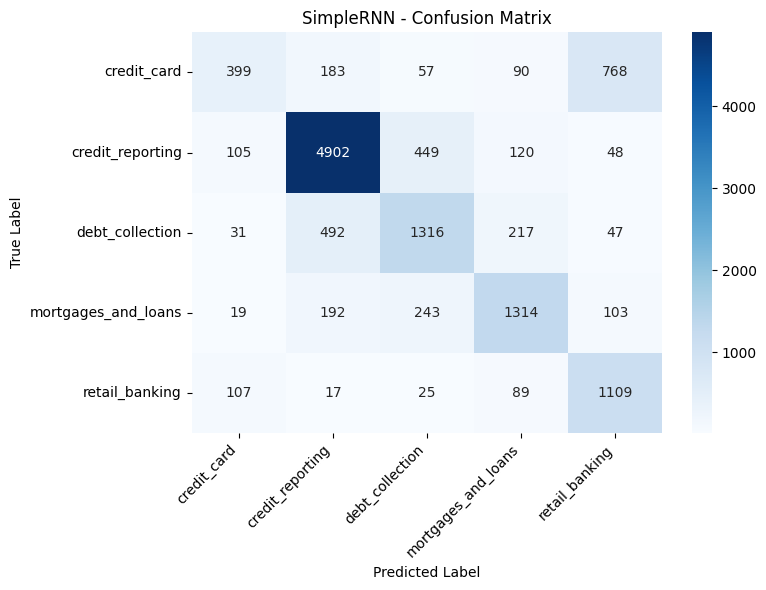

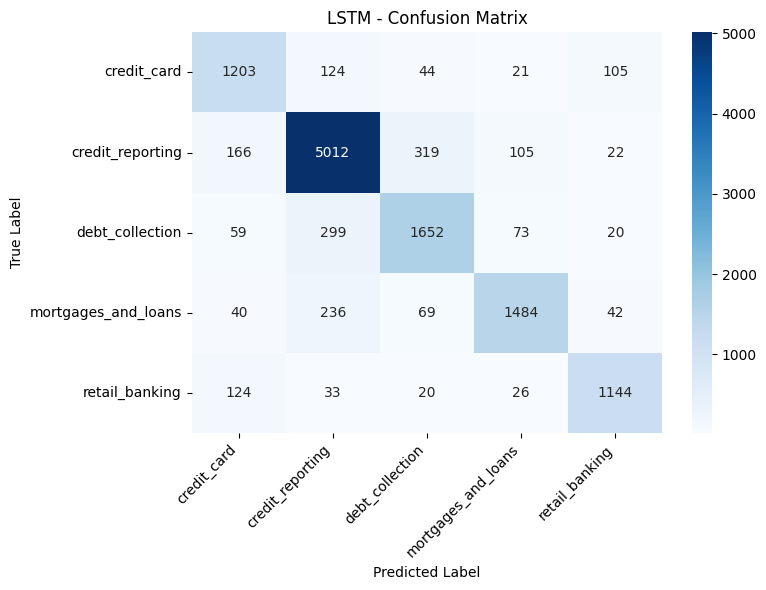

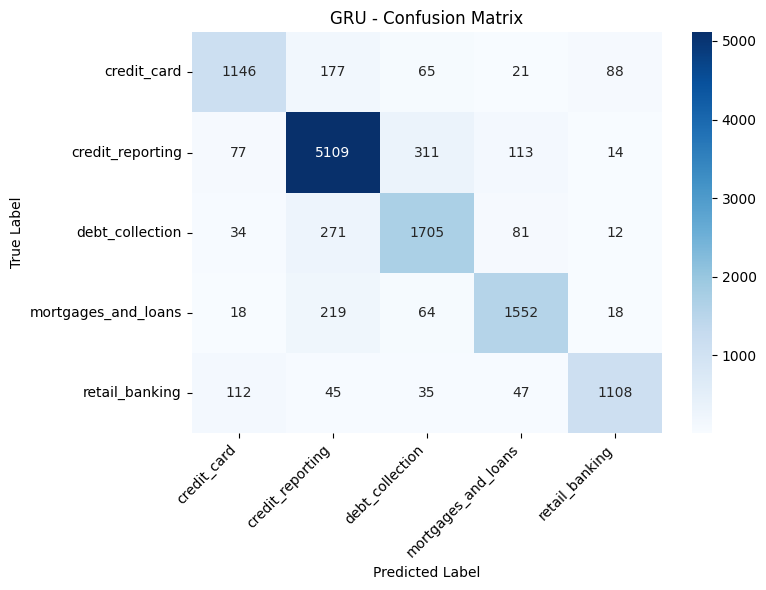

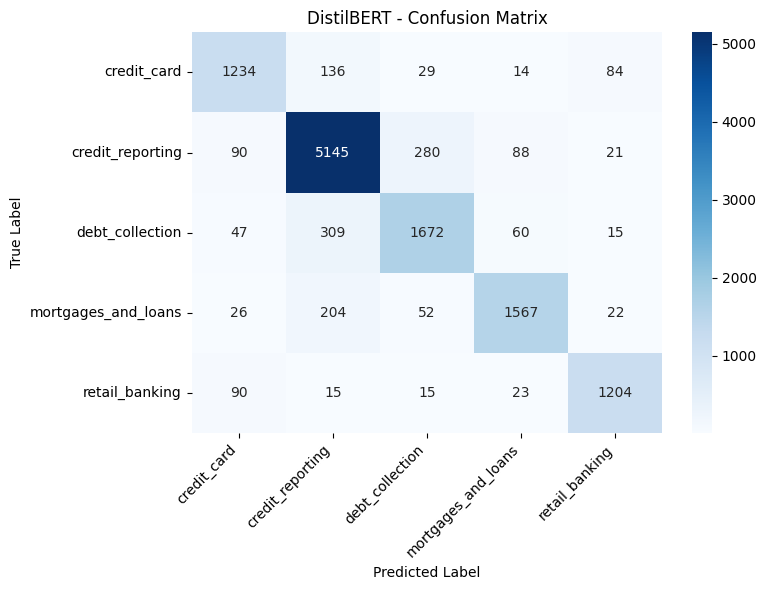

In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

PROJECT_DIR = "/content/drive/MyDrive/Consumer_Complaint_Classification"

results = []
confusion_matrices = {}

# Evaluate RNN models
for model_name in ["SimpleRNN", "LSTM", "GRU"]:

    model_path = os.path.join(PROJECT_DIR, f"{model_name}_best.keras")
    model = tf.keras.models.load_model(model_path)

    probabilities = model.predict(X_test_seq, batch_size=128, verbose=1)
    predictions = np.argmax(probabilities, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test_encoded, predictions, average="macro", zero_division=0
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_encoded, predictions),
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

    confusion_matrices[model_name] = confusion_matrix(
        y_test_encoded, predictions
    )

# Evaluate DistilBERT
transformer_path = os.path.join(PROJECT_DIR, "DistilBERT_best")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transformer_tokenizer = AutoTokenizer.from_pretrained(transformer_path)
transformer_model = AutoModelForSequenceClassification.from_pretrained(
    transformer_path
).to(device)

transformer_model.eval()

transformer_predictions = []

texts = X_test.astype(str).tolist()

for start in range(0, len(texts), 32):
    batch = texts[start:start + 32]

    inputs = transformer_tokenizer(
        batch,
        truncation=True,
        max_length=256,
        padding=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = transformer_model(**inputs)

    transformer_predictions.extend(
        torch.argmax(outputs.logits, dim=1).cpu().numpy()
    )

transformer_predictions = np.array(transformer_predictions)

precision, recall, f1, _ = precision_recall_fscore_support(
    label_encoder.transform(y_test),
    transformer_predictions,
    average="macro",
    zero_division=0
)

results.append({
    "Model": "DistilBERT",
    "Accuracy": accuracy_score(
        label_encoder.transform(y_test), transformer_predictions
    ),
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
})

confusion_matrices["DistilBERT"] = confusion_matrix(
    label_encoder.transform(y_test),
    transformer_predictions
)

# Display comparison
comparison_df = pd.DataFrame(results).sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

print("FINAL TEST SET COMPARISON")
display(comparison_df.round(4))

# Confusion matrices
for model_name, matrix in confusion_matrices.items():
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [ ]:
def predict_complaint(text):
    inputs = transformer_tokenizer(
        text,
        truncation=True,
        max_length=256,
        padding=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = transformer_model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=1)
    predicted_id = torch.argmax(probabilities, dim=1).item()

    return {
        "Predicted Category": label_encoder.inverse_transform([predicted_id])[0],
        "Confidence": f"{probabilities[0][predicted_id].item() * 100:.2f}%"
    }


sample_complaint = """
I noticed an unauthorized transaction on my credit card statement.
I contacted the bank but the issue has not been resolved.
"""

result = predict_complaint(sample_complaint)

print("Complaint:", sample_complaint)
print("Prediction:", result["Predicted Category"])
print("Confidence:", result["Confidence"])

Complaint: 
I noticed an unauthorized transaction on my credit card statement.
I contacted the bank but the issue has not been resolved.

Prediction: credit_card
Confidence: 66.42%


In [ ]:
!pip install -q gradio

import gradio as gr

def classify_complaint(complaint):
    if not complaint or not complaint.strip():
        return "Please enter a complaint.", {}

    inputs = transformer_tokenizer(
        complaint,
        truncation=True,
        max_length=256,
        padding=True,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = transformer_model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=1)[0]

    results = {
        label: float(probabilities[i])
        for i, label in enumerate(label_encoder.classes_)
    }

    predicted_category = max(results, key=results.get)
    confidence = results[predicted_category] * 100

    return (
        f"Predicted Category: {predicted_category}\nConfidence: {confidence:.2f}%",
        results
    )


demo = gr.Interface(
    fn=classify_complaint,
    inputs=gr.Textbox(
        lines=6,
        placeholder="Enter your consumer complaint here...",
        label="Consumer Complaint"
    ),
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Label(label="Category Probabilities")
    ],
    title="Consumer Complaint Classification",
    description="AI-powered complaint classification using Fine-Tuned DistilBERT.",
    examples=[
        ["I noticed an unauthorized transaction on my credit card statement."],
        ["My credit report contains incorrect information."],
        ["A debt collector keeps calling me about a debt I do not owe."]
    ]
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://97bbb5f28871b4a119.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
